In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
df = pd.read_csv('well_18_ml_v1.csv')
df.head()

,wellName,DEPTH,CGR,CPERM,CPHI,DT,DTSM,Facies,GR,MSFL,NPHI,PEF,Perm_Buckles_UpAs,PHIE,RHOB,RT,SWE,ZONE_NAME,net_gross
0,A-18-00,852.857,4.91913,-9999.0,-9999.0000,74.5270,121.9698,1,33.3418,5.79568,0.079834,4.783249,0.931011,0.072167,2.74411,10.27150,0.737652,U.Asmari,gross
1,A-18-00,853.010,9.99433,-9999.0,-9999.0000,88.8155,141.6838,1,53.4034,2.36973,0.151655,4.399977,9.209792,0.146527,2.61065,2.98569,0.667624,U.Asmari,gross
2,A-18-00,853.162,20.56400,-9999.0,-9999.0000,99.0574,166.7016,5,72.0957,1.31614,0.231567,4.030700,1.601786,0.220162,2.47339,1.38781,0.643816,U.Asmari,gross
3,A-18-00,853.314,31.71550,-9999.0,-9999.0000,104.7870,182.5868,5,78.3783,1.20371,0.287493,3.732858,3.690761,0.276589,2.35818,1.22050,0.541710,U.Asmari,net
4,A-18-00,853.467,37.70880,-9999.0,0.4288,104.8980,185.0199,5,70.4172,1.42773,0.297283,3.520631,5.106259,0.301175,2.29512,1.55953,0.438343,U.Asmari,net


In [4]:
df.replace(-9999, np.nan, inplace=True)

In [5]:
df.head()

,wellName,DEPTH,CGR,CPERM,CPHI,DT,DTSM,Facies,GR,MSFL,NPHI,PEF,Perm_Buckles_UpAs,PHIE,RHOB,RT,SWE,ZONE_NAME,net_gross
0,A-18-00,852.857,4.91913,NaN,NaN,74.5270,121.9698,1.0,33.3418,5.79568,0.079834,4.783249,0.931011,0.072167,2.74411,10.27150,0.737652,U.Asmari,gross
1,A-18-00,853.010,9.99433,NaN,NaN,88.8155,141.6838,1.0,53.4034,2.36973,0.151655,4.399977,9.209792,0.146527,2.61065,2.98569,0.667624,U.Asmari,gross
2,A-18-00,853.162,20.56400,NaN,NaN,99.0574,166.7016,5.0,72.0957,1.31614,0.231567,4.030700,1.601786,0.220162,2.47339,1.38781,0.643816,U.Asmari,gross
3,A-18-00,853.314,31.71550,NaN,NaN,104.7870,182.5868,5.0,78.3783,1.20371,0.287493,3.732858,3.690761,0.276589,2.35818,1.22050,0.541710,U.Asmari,net
4,A-18-00,853.467,37.70880,NaN,0.4288,104.8980,185.0199,5.0,70.4172,1.42773,0.297283,3.520631,5.106259,0.301175,2.29512,1.55953,0.438343,U.Asmari,net


In [6]:
dfm= df[['NPHI', 'RHOB', 'DT', 'GR', 'PHIE', 'ZONE_NAME', 'net_gross', 'Facies']].dropna()

dfm.head()


,NPHI,RHOB,DT,GR,PHIE,ZONE_NAME,net_gross,Facies
0,0.079834,2.74411,74.5270,33.3418,0.072167,U.Asmari,gross,1.0
1,0.151655,2.61065,88.8155,53.4034,0.146527,U.Asmari,gross,1.0
2,0.231567,2.47339,99.0574,72.0957,0.220162,U.Asmari,gross,5.0
3,0.287493,2.35818,104.7870,78.3783,0.276589,U.Asmari,net,5.0
4,0.297283,2.29512,104.8980,70.4172,0.301175,U.Asmari,net,5.0


In [7]:
dfm.count()

NPHI         664
RHOB         664
DT           664
GR           664
PHIE         664
ZONE_NAME    664
net_gross    664
Facies       664
dtype: int64

<Axes: xlabel='DT', ylabel='PHIE'>

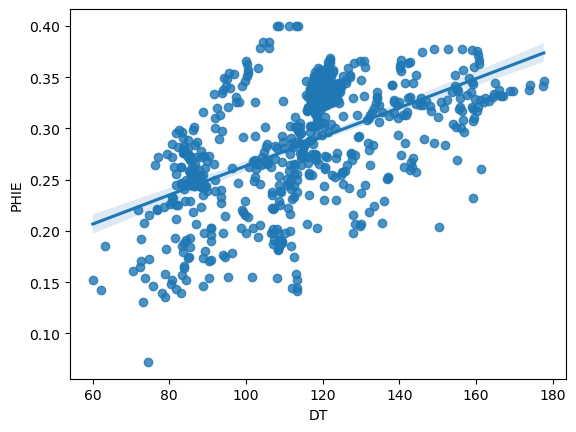

In [8]:
sns.regplot(x='DT', y='PHIE', data=dfm)

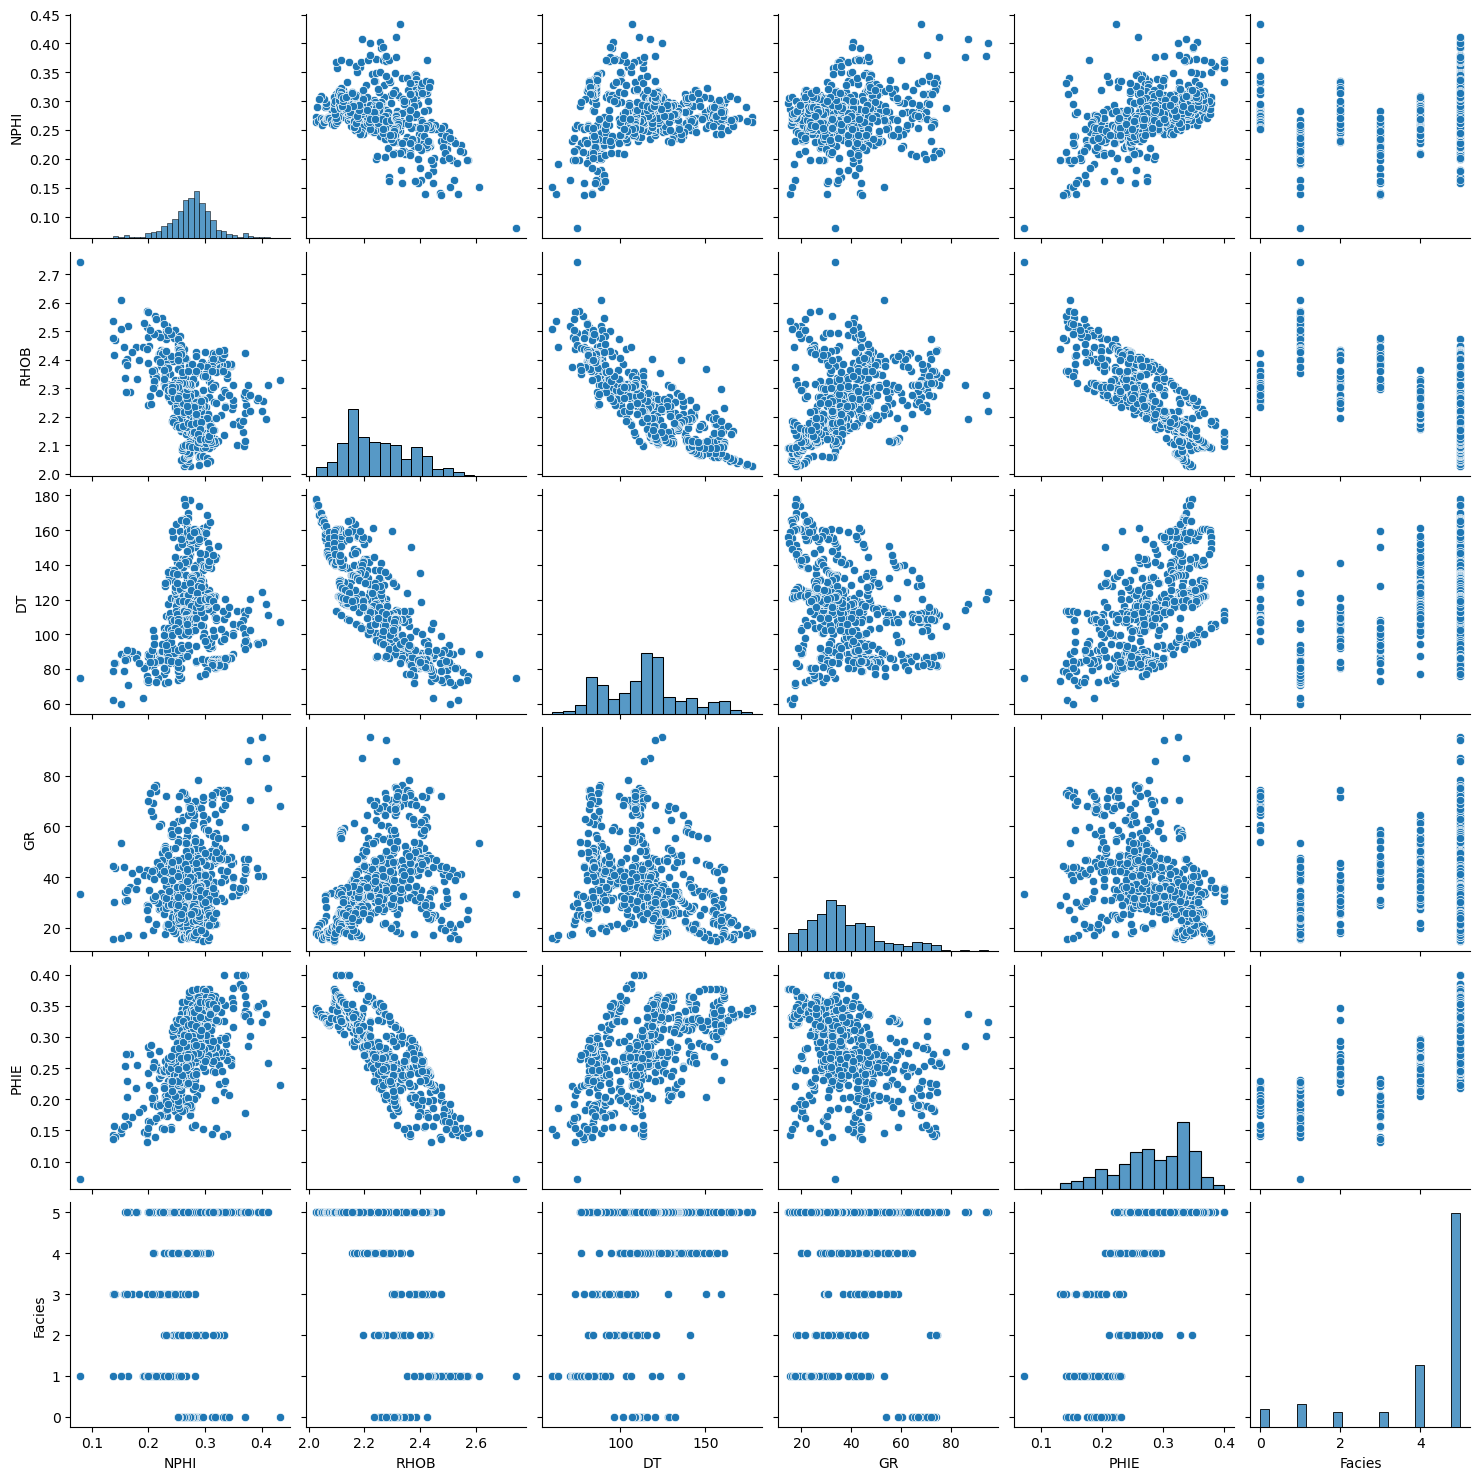

In [9]:
sns.pairplot(dfm)

In [10]:
dfm.corr(numeric_only=True)

,NPHI,RHOB,DT,GR,PHIE,Facies
NPHI,1.000000,-0.396963,0.195126,0.165611,0.557664,0.284477
RHOB,-0.396963,1.000000,-0.822232,0.381914,-0.840225,-0.564508
DT,0.195126,-0.822232,1.000000,-0.337350,0.547446,0.322223
GR,0.165611,0.381914,-0.337350,1.000000,-0.439440,-0.302250
PHIE,0.557664,-0.840225,0.547446,-0.439440,1.000000,0.773145
Facies,0.284477,-0.564508,0.322223,-0.302250,0.773145,1.000000


In [11]:
X= dfm.iloc[:, [0,1,2,3]]
y= dfm.iloc[:, -4]

In [12]:
y

0      0.072167
1      0.146527
2      0.220162
3      0.276589
4      0.301175
         ...   
730    0.327041
731    0.292937
732    0.261249
733    0.240001
734    0.226760
Name: PHIE, Length: 664, dtype: float64

In [13]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25)

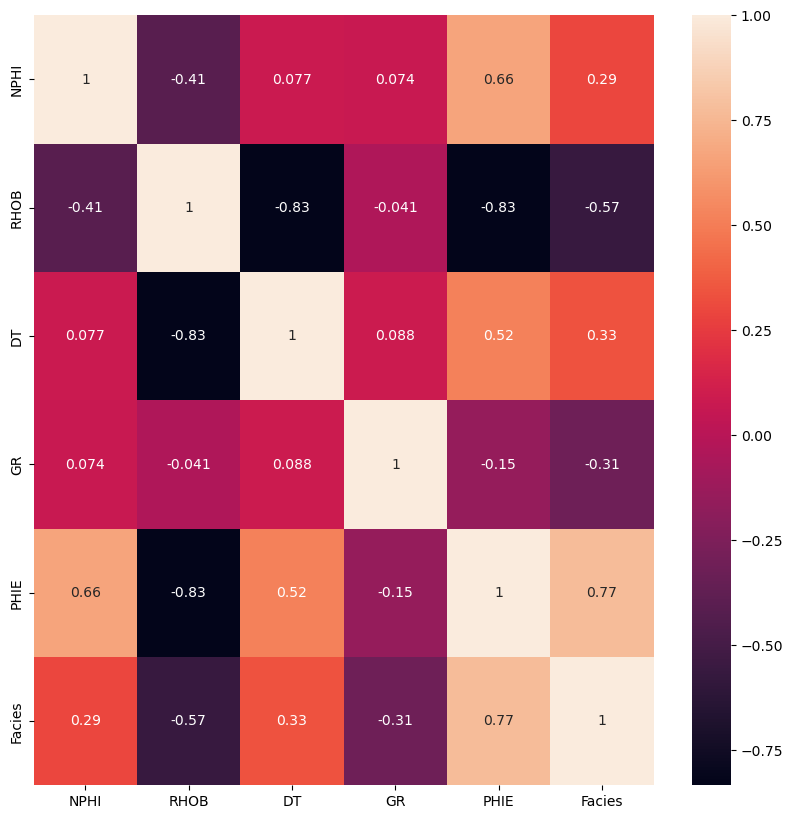

In [14]:
corrmat= dfm.corr(numeric_only=True)
top_corr= corrmat.index
plt.figure(figsize=(10,10))
g= sns.heatmap(df[top_corr].corr(numeric_only=True),annot=True)

In [15]:
print(f'shape of X_train: {X_train.shape}')
print(f'shape of y_train: {y_train.shape}')
print(f'shape of X_test: {X_test.shape}')
print(f'shape of y_test: {y_test.shape}')

shape of X_train: (498, 4)
shape of y_train: (498,)
shape of X_test: (166, 4)
shape of y_test: (166,)


In [16]:
from sklearn import metrics
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, mean_absolute_error, mean_squared_error

def reg_metrics (test, pred):
    
    print(f'MAE: {mean_absolute_error(test, pred)}')
    print(f'MSE: {mean_squared_error(test, pred)}')
    print(f'RMSE: {np.sqrt(mean_squared_error(test, pred))}')
    print(f'R2: {metrics.r2_score(test, pred)}')

def reg_plot (test, pred):
    sns.regplot(x=test, y=pred, scatter_kws={'color':'black'}, line_kws={'color':'red'})
    plt.xlim(0,max(test ))
    plt.ylim(0,max(pred ))
    plt.show()
    
def scatter_plot_comparison (test, pred):
    sns.scatterplot(x=test.index, y=test.values, color='red', label='Test data')
    sns.scatterplot(x=test.index, y=pred, color='blue', label='Predicted data')
    plt.show()

def line_plot_comparison (test, pred):
    plt.plot(test.values, color='red', label='Test data')
    plt.plot(pred, color='blue', label='Predicted data')
    plt.show()

Linear Regression model score: 1.333833268447502
Linear Regression model score: [ 0.42474988 -0.45291519 -0.00093212 -0.00110788]
MAE: 0.017312885778802564
MSE: 0.0005630776327561606
RMSE: 0.02372925689431004
R2: 0.8459286462519937


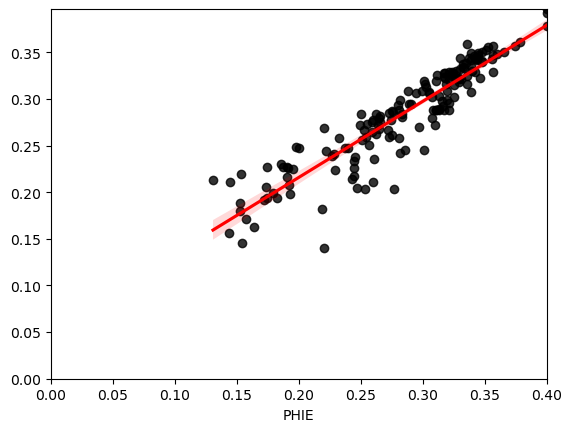

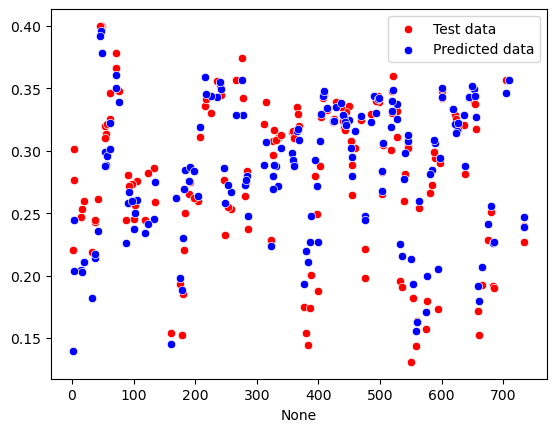

In [17]:
from sklearn.linear_model import LinearRegression
lin_reg= LinearRegression()
lin_reg.fit(X_train, y_train)
print(f'Linear Regression model score: {lin_reg.intercept_}')
print(f'Linear Regression model score: {lin_reg.coef_}')
y_pred_lin= lin_reg.predict(X_test)
reg_metrics(y_test, y_pred_lin)
reg_plot(y_test, y_pred_lin)
scatter_plot_comparison(y_test, y_pred_lin)

MAE: 0.03280139270270306
MSE: 0.0018088568037054262
RMSE: 0.04253065722164926
R2: 0.50505400983691


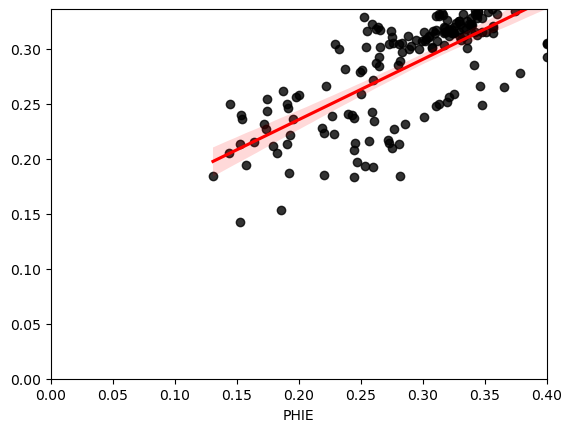

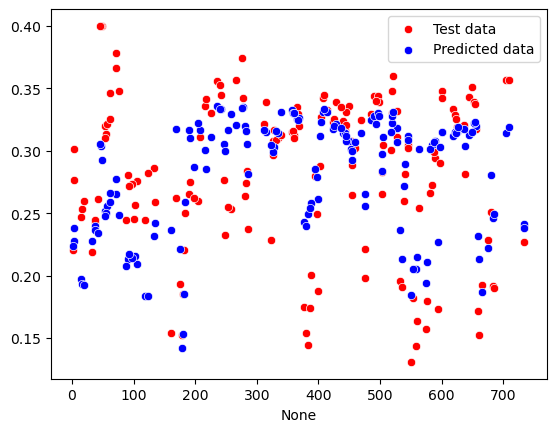

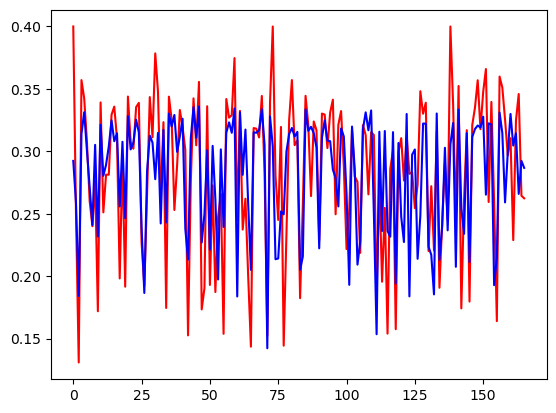

In [18]:
from sklearn.svm import SVR, SVC
svr_reg= SVR(kernel='rbf')
svr_reg.fit(X_train, y_train)
y_pred_svr= svr_reg.predict(X_test)
reg_metrics(y_test, y_pred_svr)
reg_plot(y_test, y_pred_svr)
scatter_plot_comparison(y_test, y_pred_svr)
line_plot_comparison(y_test, y_pred_svr)


MAE: 0.014797937349397591
MSE: 0.0007433642514373494
RMSE: 0.02726470706678048
R2: 0.796597964678126


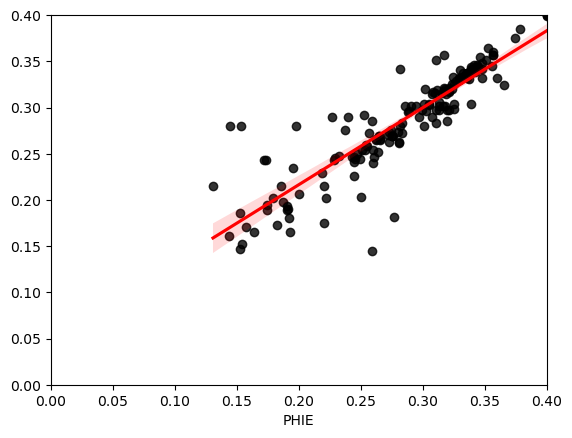

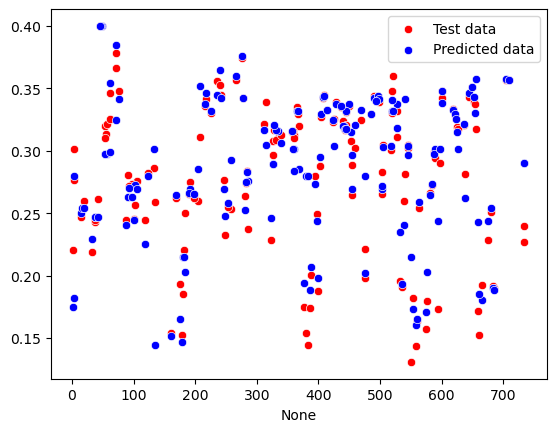

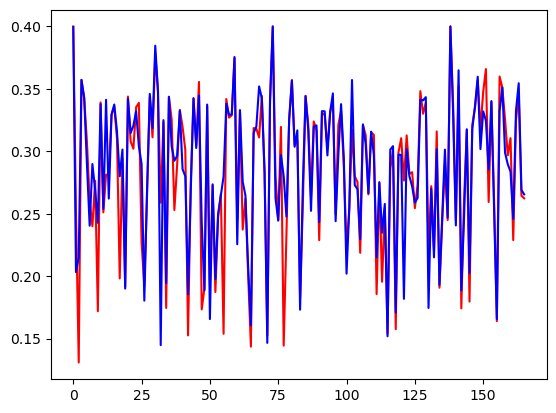

In [19]:
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
dtr_reg= DecisionTreeRegressor()
dtr_reg.fit(X_train, y_train)
y_pred_dtr= dtr_reg.predict(X_test)
reg_metrics(y_test, y_pred_dtr)
reg_plot(y_test, y_pred_dtr)
scatter_plot_comparison(y_test, y_pred_dtr)
line_plot_comparison(y_test, y_pred_dtr)

MAE: 0.010605674813253021
MSE: 0.0003282315933196235
RMSE: 0.018117162948972542
R2: 0.9101880753492492


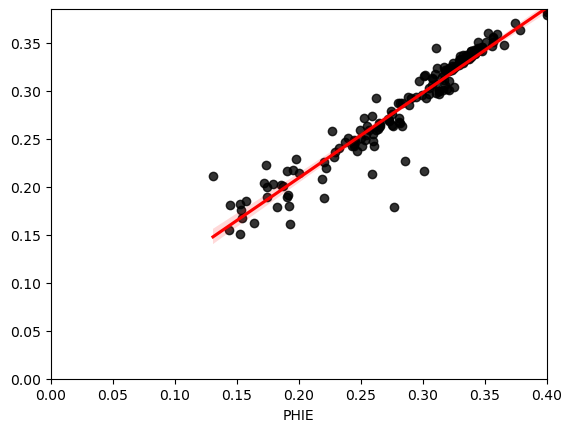

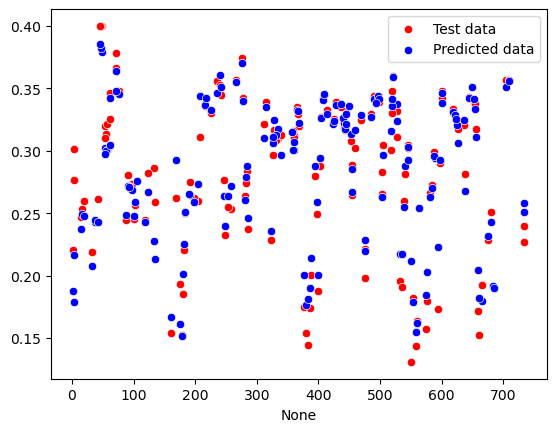

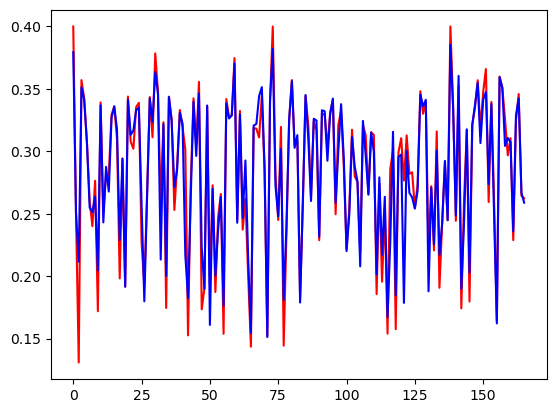

In [20]:
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
rfr_reg= RandomForestRegressor()
rfr_reg.fit(X_train, y_train)
y_pred_rfr= rfr_reg.predict(X_test)
reg_metrics(y_test, y_pred_rfr)
reg_plot(y_test, y_pred_rfr)
scatter_plot_comparison(y_test, y_pred_rfr)
line_plot_comparison(y_test, y_pred_rfr)


In [21]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


MAE: 0.010648561877255268
MSE: 0.0003198627508991277
RMSE: 0.017884707179574612
R2: 0.91247798850868


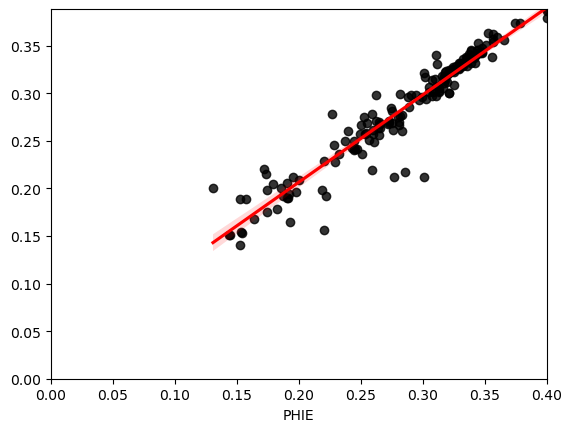

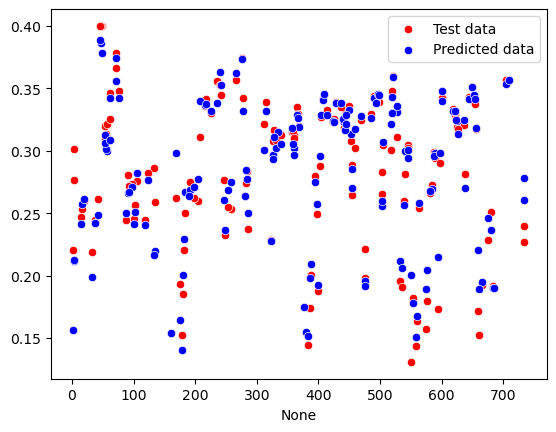

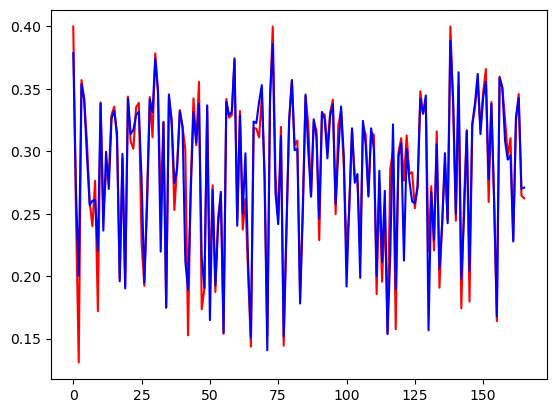

In [22]:
import xgboost as xgb
xgb_reg= xgb.XGBRegressor()
xgb_reg.fit(X_train, y_train)
y_pred_xgb= xgb_reg.predict(X_test)
reg_metrics(y_test, y_pred_xgb)
reg_plot(y_test, y_pred_xgb)
scatter_plot_comparison(y_test, y_pred_xgb)
line_plot_comparison(y_test, y_pred_xgb)


In [23]:
dfm.head()

,NPHI,RHOB,DT,GR,PHIE,ZONE_NAME,net_gross,Facies
0,0.079834,2.74411,74.5270,33.3418,0.072167,U.Asmari,gross,1.0
1,0.151655,2.61065,88.8155,53.4034,0.146527,U.Asmari,gross,1.0
2,0.231567,2.47339,99.0574,72.0957,0.220162,U.Asmari,gross,5.0
3,0.287493,2.35818,104.7870,78.3783,0.276589,U.Asmari,net,5.0
4,0.297283,2.29512,104.8980,70.4172,0.301175,U.Asmari,net,5.0


In [24]:
dfl= dfm[['NPHI', 'RHOB', 'DT', 'GR','PHIE', 'net_gross' ]]

In [25]:
dfl['net_gross'].value_counts()

net_gross
net      481
gross    183
Name: count, dtype: int64

In [26]:
Xl= dfl.iloc[:, [0,1,2,3,4]]
yl= dfl.iloc[:, -1]
Xl_train, Xl_test, yl_train, yl_test = train_test_split(Xl, yl, test_size=0.25)

In [27]:
Xl.columns

Index(['NPHI', 'RHOB', 'DT', 'GR', 'PHIE'], dtype='object')

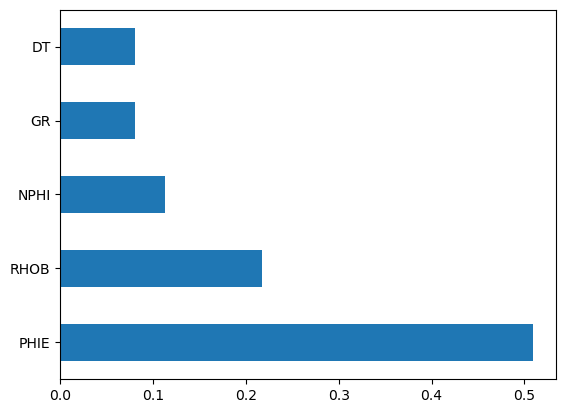

In [28]:
from sklearn.ensemble import ExtraTreesClassifier
model= ExtraTreesClassifier()
model.fit(Xl, yl)
f1= pd.Series(model.feature_importances_, index=Xl.columns)
f1.nlargest(10).plot(kind='barh')
plt.show()


In [29]:
import sklearn
print(sklearn.__file__)


c:\Users\Edison\anaconda3\Lib\site-packages\sklearn\__init__.py


In [30]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [60]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
yl= le.fit_transform(yl)
print(f'Encoded labels: {yl}')

Encoded labels: [0 0 0 1 1 1 1 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 0 0 0 1 1 1 1 0 0 0 0 0
 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 0 0 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 0 1 1 1 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 0 0 0 0 1 1 1 1 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 0 0 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 0 

In [62]:
Xl_train, Xl_test, yl_train, yl_test = train_test_split(Xl, yl, test_size=0.25)
print(f'shape of Xl_train: {yl_test}')


shape of Xl_train: [1 1 1 0 1 1 1 1 1 1 1 0 1 1 1 1 0 0 0 1 1 1 1 0 0 1 1 1 1 0 1 1 0 1 1 1 0
 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 0 0 1 0 1 1 0 1 1
 0 1 1 1 0 1 0 1 1 0 1 1 1 1 1 1 0 0 1 1 1 0 1 0 1 1 1 0 1 1 1 1 1 0 1 0 0
 1 1 1 0 1 1 1 1 1 1 1 1 1 1 0 0 1 1 1 1 1 0 1 1 1 0 1 1 1 1 1 1 0 1 1 1 0
 1 1 1 1 1 1 1 1 1 0 0 1 1 1 1 1 0 0]


In [63]:
Xl_train, Xl_test, yl_train, yl_test = train_test_split(Xl, yl, test_size=0.25)
print(f'shape of Xl_train: {Xl_train.shape}')
print(f'shape of yl_train: {yl_train.shape}')
print(f'shape of Xl_test: {Xl_test.shape}')
print(f'shape of yl_test: {yl_test.shape}')

shape of Xl_train: (498, 5)
shape of yl_train: (498,)
shape of Xl_test: (166, 5)
shape of yl_test: (166,)


In [64]:
print(yl_test)

[1 0 1 1 1 1 1 1 1 0 0 1 1 0 0 1 0 1 1 1 0 1 1 1 1 0 1 0 0 1 1 0 1 1 1 1 0
 1 1 1 0 1 0 1 1 1 0 1 1 1 1 0 0 1 0 1 0 1 1 1 0 0 1 1 1 1 1 1 1 1 0 1 1 1
 0 1 1 1 1 1 0 1 0 1 1 1 0 1 1 0 1 1 0 0 1 0 1 0 1 1 1 1 1 1 0 1 1 1 1 1 1
 0 1 0 1 0 0 0 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 0 1 1 1 1 1 1 0 1 1 0 1 1 0
 0 1 1 1 1 0 1 1 0 1 1 0 0 0 1 1 1 0]


In [65]:
from sklearn.linear_model import LinearRegression
classifier= LinearRegression()
classifier.fit(Xl_train, yl_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[-0.81, 0.36, 0. , 0. , 7.04]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['NPHI','RHOB','DT','GR','PHIE']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-2.071
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,5


In [66]:
yl_pred= classifier.predict(Xl_test)

In [67]:
yl_pred = (yl_pred >= 0.5).astype(int)

In [68]:
yl_pred 

array([1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1,
       1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1,
       1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1,
       1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1,
       1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0,
       1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0])

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix 
cm = confusion_matrix(yl_test, yl_pred)
print(f'Confusion Matrix:\n{cm}')
accuracy= accuracy_score(yl_test, yl_pred)
accuracy= accuracy_score(yl_test, yl_pred)
print(f'Accuracy of the model: {accuracy*100:.2f}%')

[[ 44   5]
 [  0 117]]
Accuracy of the model: 96.99%


In [75]:
from sklearn.neighbors import KNeighborsClassifier
classifier_k= KNeighborsClassifier(n_neighbors=5)
classifier_k.fit(Xl_train, yl_train)
yk_pred= classifier_k.predict(Xl_test)
cm_k = confusion_matrix(yl_test, yk_pred)
print(f'Confusion Matrix:\n{cm_k}')
accuracy_k= accuracy_score(yl_test, yk_pred)
print(f'Accuracy of the model: {accuracy_k*100:.2f}%')

Confusion Matrix:
[[ 34  15]
 [  7 110]]
Accuracy of the model: 86.75%


In [77]:

classifier_f= RandomForestClassifier(n_estimators=100)
classifier_f.fit(Xl_train, yl_train)
yf_pred= classifier_f.predict(Xl_test)
cm_f = confusion_matrix(yl_test, yf_pred)
print(f'Confusion Matrix:\n{cm_f}')
accuracy_f= accuracy_score(yl_test, yf_pred)
print(f'Accuracy of the model: {accuracy_f*100:.2f}%')

Confusion Matrix:
[[ 47   2]
 [  0 117]]
Accuracy of the model: 98.80%
